<a href="https://colab.research.google.com/github/Khadeeja-beevi12/Resistor/blob/main/resistor.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

/tmp/ipykernel_4733/171368715.py:507: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: css. Please pass these parameters to launch() instead.
  with gr.Blocks(css=custom_css, title="Resistor AI Detective") as demo:


🚀 Starting Resistor AI Detective...
Please wait for Gradio to create the public link.
Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://6a1fb7c2b95d4a3049.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)



✅ Resistor AI Detective is running!
🔗 Public URL: https://6a1fb7c2b95d4a3049.gradio.live

📱 QR CODE GENERATED!
Scan this QR code to open your Resistor AI Detective prototype.


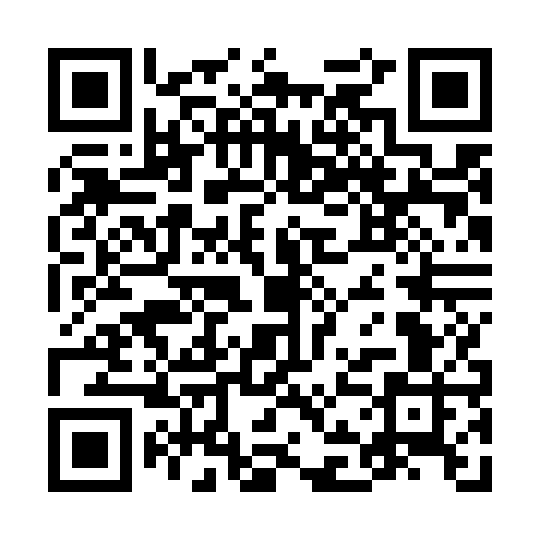


🧪 Test the QR code with your phone before using it in the manual.
⚠️ Keep this Colab session running while testing the public link.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [3]:
# RESISTOR AI DETECTIVE
# Student Mini-Game + Resistor Decoder + Automatic QR Code
# Google Colab version


!pip -q install -U gradio "qrcode[pil]"

import gradio as gr
import random
import math
import qrcode
import os
import re
import numpy as np
import wave
from IPython.display import display, Audio
from google.colab import files


# 1. RESISTOR COLOUR CODE


DIGITS = {
    "Black": 0, "Brown": 1, "Red": 2, "Orange": 3,
    "Yellow": 4, "Green": 5, "Blue": 6, "Violet": 7,
    "Grey": 8, "White": 9
}

MULTIPLIERS = {
    "Black": 1, "Brown": 10, "Red": 100, "Orange": 1000,
    "Yellow": 10000, "Green": 100000, "Blue": 1000000,
    "Violet": 10000000, "Grey": 100000000,
    "White": 1000000000
}

TOLERANCES = {
    "Brown": "±1%", "Red": "±2%",
    "Gold": "±5%", "Silver": "±10%"
}

BAND_COLORS = list(DIGITS.keys())
TOLERANCE_COLORS = list(TOLERANCES.keys())

CSS_COLORS = {
    "Black": "#111111", "Brown": "#7A3E00",
    "Red": "#E53935", "Orange": "#F57C00",
    "Yellow": "#FBC02D", "Green": "#2E7D32",
    "Blue": "#1565C0", "Violet": "#7B1FA2",
    "Grey": "#757575", "White": "#F5F5F5",
    "Gold": "#D4AF37", "Silver": "#BDBDBD"
}


# 2. RESISTOR CHALLENGES


RESISTOR_CHALLENGES = [
    ("Brown", "Black", "Brown", "Gold"),    # 100 Ω
    ("Red", "Red", "Brown", "Gold"),        # 220 Ω
    ("Orange", "Orange", "Brown", "Gold"),  # 330 Ω
    ("Yellow", "Violet", "Brown", "Gold"),  # 470 Ω
    ("Green", "Blue", "Brown", "Gold"),     # 560 Ω
    ("Brown", "Black", "Red", "Gold"),      # 1 kΩ
    ("Red", "Red", "Red", "Gold"),          # 2.2 kΩ
    ("Yellow", "Violet", "Red", "Gold"),    # 4.7 kΩ
    ("Brown", "Black", "Orange", "Gold"),   # 10 kΩ
    ("Brown", "Red", "Orange", "Gold"),     # 12 kΩ
    ("Red", "Red", "Orange", "Gold"),       # 22 kΩ
    ("Yellow", "Violet", "Orange", "Gold"), # 47 kΩ
    ("Green", "Blue", "Orange", "Gold"),    # 56 kΩ
]


# 3. CALCULATIONS AND ANSWER FORMATTING


def calculate_resistor(bands):
    b1, b2, multiplier, tolerance = bands
    resistance = (DIGITS[b1] * 10 + DIGITS[b2]) * MULTIPLIERS[multiplier]
    return resistance, TOLERANCES.get(tolerance, "")


def format_resistance(value):
    if value >= 1_000_000:
        return f"{value / 1_000_000:g} MΩ"
    if value >= 1_000:
        return f"{value / 1_000:g} kΩ"
    return f"{value:g} Ω"


def normalize_answer(text):
    if text is None:
        return None

    text = str(text).strip().lower()
    text = text.replace(" ", "")
    text = text.replace("ohms", "").replace("ohm", "")
    text = text.replace("ω", "")

    try:
        if text.endswith("k"):
            return float(text[:-1]) * 1_000

        # M or m at the end means megaohms in this activity.
        if text.endswith("m"):
            return float(text[:-1]) * 1_000_000

        return float(text)
    except (ValueError, TypeError):
        return None


# 4. RESISTOR VISUAL


def create_resistor_html(bands):
    b1, b2, b3, b4 = bands

    band_html = "".join(
        f'<div class="resistor-band" style="background:{CSS_COLORS[c]}"></div>'
        for c in [b1, b2, b3]
    )

    tolerance_html = (
        f'<div class="resistor-band tolerance-band" '
        f'style="background:{CSS_COLORS[b4]}"></div>'
    )

    return f"""
    <div class="resistor-stage">
        <div class="resistor-wire"></div>
        <div class="resistor-body">
            {band_html}
            <div class="resistor-spacer"></div>
            {tolerance_html}
        </div>
        <div class="resistor-wire"></div>
    </div>
    <div class="resistor-caption">
        🔎 Observe the four colour bands carefully
    </div>
    """


def make_challenge(previous=None):
    choices = [x for x in RESISTOR_CHALLENGES if x != previous]
    return random.choice(choices or RESISTOR_CHALLENGES)


# 5. CELEBRATION SOUND FILE


def create_celebration_sound(path="hurray_sound.wav"):
    sample_rate = 22050
    notes = [523.25, 659.25, 783.99, 1046.50]
    parts = []

    for frequency in notes:
        duration = 0.18
        t = np.linspace(0, duration, int(sample_rate * duration), False)
        envelope = np.linspace(0.7, 0.0, len(t))
        tone = 0.35 * np.sin(2 * np.pi * frequency * t) * envelope
        parts.append(tone)

    audio = np.concatenate(parts)
    audio = (audio * 32767).astype(np.int16)

    with wave.open(path, "wb") as wav:
        wav.setnchannels(1)
        wav.setsampwidth(2)
        wav.setframerate(sample_rate)
        wav.writeframes(audio.tobytes())

    return path


SOUND_FILE = create_celebration_sound()


# 6. START GAME


def start_game():
    bands = make_challenge()
    question = """
### 🔍 Detective Challenge

Look carefully at the resistor above.

**What is its resistance value?**

Enter your answer below.

Example: `4.7 kΩ`
"""
    return (
        bands,
        create_resistor_html(bands),
        question,
        "",
        "",
        0,
        0,
        gr.update(visible=False),
        gr.update(visible=False),
        gr.update(value="", visible=False),
        gr.update(value=None, visible=False)
    )


# 7. CHECK ANSWER


def check_answer(answer, bands, score, attempts):
    score = int(score or 0)
    attempts = int(attempts or 0)

    if bands is None:
        return (
            "⚠️ Please start a challenge first.",
            score, attempts,
            gr.update(visible=False),
            gr.update(visible=False),
            gr.update(visible=False),
            gr.update(value=None, visible=False)
        )

    correct_value, tolerance = calculate_resistor(bands)
    student_value = normalize_answer(answer)
    attempts += 1

    if student_value is None:
        return (
            """
### ⚠️ I couldn't understand that answer.

Try a format such as **100 Ω**, **1 kΩ**, or **4.7 kΩ**.

💡 Need help? Click **Give Me a Hint** or use **Detect My Resistor**.
""",
            score, attempts,
            gr.update(visible=True),
            gr.update(visible=False),
            gr.update(visible=False),
            gr.update(value=None, visible=False)
        )

    if math.isclose(student_value, correct_value, rel_tol=1e-9):
        score += 1
        message = f"""
<div class="success-card">

<h1>🎉 HURRAY!</h1>
<h2>Correct Answer! ✅</h2>

<h2>{format_resistance(correct_value)}</h2>
<p>Tolerance: <b>{tolerance}</b></p>
<h2>🏆 +1 MARK</h2>
<p>Excellent work, Detective!</p>

</div>
"""
        return (
            message,
            score, attempts,
            gr.update(visible=False),
            gr.update(visible=True),
            gr.update(visible=False),
            gr.update(value=SOUND_FILE, visible=True)
        )

    message = f"""
<div class="wrong-card">

<h2>🤔 Not quite!</h2>
<p>Your answer: <b>{format_resistance(student_value)}</b></p>

<h3>💡 Here's a hint</h3>
<p>The first two bands give the first two digits.</p>
<p>The third band tells you the multiplier.</p>
<p>Use <b>Detect My Resistor</b> if you need a step-by-step explanation.</p>

</div>
"""
    return (
        message,
        score, attempts,
        gr.update(visible=True),
        gr.update(visible=False),
        gr.update(visible=False),
        gr.update(value=None, visible=False)
    )


# 8. DETECT MY RESISTOR


def detect_my_resistor(first_digit, second_digit, multiplier, tolerance):
    if not all([first_digit, second_digit, multiplier, tolerance]):
        return "⚠️ Please select all four colour bands."

    d1 = DIGITS[first_digit]
    d2 = DIGITS[second_digit]
    multiplier_value = MULTIPLIERS[multiplier]
    resistance = (d1 * 10 + d2) * multiplier_value
    tolerance_value = TOLERANCES[tolerance]

    return f"""
<div class="decode-result">

<h2>🧠 Resistor Detective Result</h2>

<p><b>① First Digit:</b> {first_digit} → {d1}</p>
<p><b>② Second Digit:</b> {second_digit} → {d2}</p>
<p><b>③ Multiplier:</b> {multiplier} → × {multiplier_value:g}</p>
<p><b>④ Tolerance:</b> {tolerance} → {tolerance_value}</p>

<hr>

<h3>🔢 Calculation</h3>
<h2>({d1}{d2}) × {multiplier_value:g} = {format_resistance(resistance)}</h2>
<p>Tolerance: <b>{tolerance_value}</b></p>

<h3>🎯 Your resistor value is {format_resistance(resistance)} {tolerance_value}</h3>

</div>
"""


# 9. HINT


def show_hint(bands):
    if bands is None:
        return gr.update(value="Start a challenge first.", visible=True)

    b1, b2, b3, b4 = bands
    return gr.update(value=f"""
<div class="hint-card">

<h2>💡 Detective Hint</h2>
<p>Read the resistor from <b>left to right</b>.</p>

<p><b>Band 1 — {b1}</b>: digit {DIGITS[b1]}</p>
<p><b>Band 2 — {b2}</b>: digit {DIGITS[b2]}</p>
<p><b>Band 3 — {b3}</b>: multiplier × {MULTIPLIERS[b3]:g}</p>
<p><b>Band 4 — {b4}</b>: tolerance {TOLERANCES[b4]}</p>

<p>Now combine the first two digits and multiply by the third band.</p>
<p><b>Try decoding it yourself!</b></p>

</div>
""", visible=True)


# 10. NEXT CHALLENGE


def next_challenge(current_bands, score, attempts):
    bands = make_challenge(current_bands)

    question = """
### 🔍 New Detective Challenge

A new resistor has appeared!

**What is its resistance?**

Observe the bands and enter your answer.
"""
    return (
        bands,
        create_resistor_html(bands),
        question,
        "",
        "",
        score,
        attempts,
        gr.update(visible=False),
        gr.update(visible=False),
        gr.update(value="", visible=False),
        gr.update(value=None, visible=False)
    )



# 11. CUSTOM CSS


custom_css = """
body {
    background: linear-gradient(135deg,#f8fbff,#ffffff,#f5f3ff);
}
.gradio-container {
    max-width:1150px!important;
    margin:auto!important;
    font-family:Inter,Arial,sans-serif;
}
.main-title {
    text-align:center;font-size:40px;font-weight:900;color:#1e293b;
}
.subtitle {
    text-align:center;color:#64748b;font-size:17px;margin-bottom:22px;
}
.activity-flow {
    font-size:17px;font-weight:700;color:#27364b;margin:8px 0 22px;
}
.game-card {
    background:rgba(255,255,255,.94);border-radius:24px;padding:24px;
    border:1px solid #e5e7eb;box-shadow:0 12px 35px #1f293714;
    margin-bottom:20px;
}
.resistor-stage {
    min-height:190px;display:flex;align-items:center;justify-content:center;
    margin:10px 0;overflow:hidden;
}
.resistor-wire {
    width:100px;height:7px;background:#9ca3af;flex-shrink:1;
}
.resistor-body {
    width:310px;min-width:230px;height:105px;border-radius:20px;
    background:linear-gradient(180deg,#f6d7a5,#d8aa68);
    display:flex;align-items:center;padding:0 28px 0 45px;
    box-sizing:border-box;box-shadow:inset 0 5px 10px #ffffff66,
    inset 0 -6px 12px #50280a2e,0 8px 18px #0000002e;
}
.resistor-band {
    width:25px;height:105px;flex-shrink:0;margin-right:15px;
    box-shadow:inset 3px 0 4px #ffffff26,inset -3px 0 4px #00000030;
}
.resistor-spacer {flex:1;}
.tolerance-band {margin-left:12px;margin-right:0;}
.resistor-caption {
    text-align:center;font-size:16px;font-weight:700;color:#64748b;
    margin-bottom:15px;
}
.answer-input input {
    font-size:21px!important;text-align:center;border-radius:14px!important;
    padding:14px!important;
}
.primary-btn,.green-btn,.orange-btn,.detect-btn {
    color:white!important;border:none!important;border-radius:14px!important;
    font-weight:800!important;min-height:50px!important;
}
.primary-btn,.detect-btn {
    background:linear-gradient(90deg,#2563eb,#7c3aed)!important;
}
.green-btn {background:linear-gradient(90deg,#059669,#10b981)!important;}
.orange-btn {background:linear-gradient(90deg,#f97316,#f59e0b)!important;}
.score-box {
    background:linear-gradient(135deg,#eefdf5,#f0fdf4);border-radius:16px;
    padding:14px;text-align:center;font-size:19px;font-weight:800;color:#166534;
}
.success-card,.wrong-card,.hint-card,.decode-result {
    border-radius:20px;padding:22px;margin-top:12px;
}
.success-card {
    background:linear-gradient(135deg,#dcfce7,#ecfdf5);
    border:2px solid #86efac;color:#166534;text-align:center;
}
.wrong-card {
    background:linear-gradient(135deg,#fff7ed,#fffbeb);
    border:2px solid #fdba74;color:#9a3412;
}
.hint-card {
    background:linear-gradient(135deg,#eff6ff,#eef2ff);
    border:2px solid #93c5fd;color:#1e3a8a;
}
.detect-section {
    background:linear-gradient(135deg,#e9edf3,#f1f5f9);
    border-radius:24px;padding:26px;margin-top:24px;border:1px solid #dbe1e8;
    box-shadow:0 10px 30px #1f293712;
}
.detect-title {font-size:27px;font-weight:850;color:#26364d;}
.detect-subtitle {color:#64748b;font-size:16px;margin:8px 0 20px;}
.band-label {
    display:inline-block;background:#e0e7ff;color:#5555e8;font-weight:800;
    border-radius:8px;padding:5px 10px;margin-bottom:8px;
}
.detect-section .wrap,.detect-section input {
    border-radius:12px!important;
}
.decode-result {
    background:white;border:2px solid #c7d2fe;color:#26364d;
    box-shadow:0 8px 25px #4f46e514;
}
.section-divider {
    height:2px;background:linear-gradient(90deg,transparent,#e2e8f0,transparent);
    margin:30px 0;
}
@media(max-width:700px) {
    .main-title {font-size:29px;}
    .resistor-wire {width:35px;}
    .resistor-body {width:230px;min-width:200px;height:80px;padding:0 18px 0 27px;}
    .resistor-band {width:18px;height:80px;margin-right:10px;}
    .tolerance-band {margin-left:8px;margin-right:0;}
    .resistor-stage {min-height:145px;}
    .detect-section {padding:16px;}
}
"""



# 12. BUILD GRADIO APP


with gr.Blocks(css=custom_css, title="Resistor AI Detective") as demo:

    resistor_state = gr.State(None)
    score_state = gr.State(0)
    attempts_state = gr.State(0)

    gr.HTML("""
    <div class="main-title">🔬 Resistor AI Detective</div>
    <div class="subtitle">Become a circuit detective and crack the resistor code!</div>
    <div class="activity-flow">
        🔎 Observe → 🎨 Decode → 🧠 Predict → ⚡ Build → 📊 Compare
    </div>
    """)

    with gr.Group(elem_classes="game-card"):
        gr.Markdown("## 🔍 Resistor Detective Challenge\nLook carefully at the resistor and identify its value.")
        resistor_image = gr.HTML()
        question = gr.Markdown("Click **Start Challenge** to begin.")

        answer = gr.Textbox(
            label="💡 Enter the resistor value",
            placeholder="Example: 4.7 kΩ",
            elem_classes="answer-input"
        )

        with gr.Row():
            check_btn = gr.Button("🔎 CHECK MY ANSWER", elem_classes="primary-btn")
            start_btn = gr.Button("🚀 START CHALLENGE", elem_classes="green-btn")

        feedback = gr.Markdown()

        with gr.Row():
            score_display = gr.Markdown('<div class="score-box">🏆 Score: 0</div>')
            attempts_display = gr.Markdown('<div class="score-box">🎯 Attempts: 0</div>')

        hint_btn = gr.Button("💡 GIVE ME A HINT", elem_classes="orange-btn", visible=False)
        hint_output = gr.Markdown(visible=False)

        next_btn = gr.Button("➡️ NEXT CHALLENGE", elem_classes="primary-btn", visible=False)

        celebration_audio = gr.Audio(
            label="🎉 Hurray!",
            type="filepath",
            autoplay=True,
            visible=False
        )

    gr.HTML('<div class="section-divider"></div>')

    with gr.Group(elem_classes="detect-section"):
        gr.HTML("""
        <div class="detect-title">🎨 Step 1 — Read Your Resistor</div>
        <div class="detect-subtitle">
        Look at the physical 4-band resistor from your kit and select its colours from left to right.
        </div>
        """)

        with gr.Row():
            with gr.Column():
                gr.HTML('<div class="band-label">① First Digit</div>')
                first_digit = gr.Dropdown(choices=BAND_COLORS, label=None, value="Yellow")
            with gr.Column():
                gr.HTML('<div class="band-label">② Second Digit</div>')
                second_digit = gr.Dropdown(choices=BAND_COLORS, label=None, value="Violet")

        with gr.Row():
            with gr.Column():
                gr.HTML('<div class="band-label">③ Multiplier</div>')
                multiplier = gr.Dropdown(choices=BAND_COLORS, label=None, value="Red")
            with gr.Column():
                gr.HTML('<div class="band-label">④ Tolerance</div>')
                tolerance = gr.Dropdown(choices=TOLERANCE_COLORS, label=None, value="Gold")

        detect_btn = gr.Button("🧠 DETECT MY RESISTOR", elem_classes="detect-btn")
        detect_result = gr.Markdown()

        gr.Markdown("👆 **Select the four colour bands**, then click **DETECT MY RESISTOR**.")

    # EVENT FUNCTIONS


    def update_score(score):
        return f'<div class="score-box">🏆 Score: {score}</div>'

    def update_attempts(attempts):
        return f'<div class="score-box">🎯 Attempts: {attempts}</div>'

    start_btn.click(
        fn=start_game,
        outputs=[
            resistor_state, resistor_image, question, feedback,
            hint_output, score_state, attempts_state, hint_btn,
            next_btn, answer, celebration_audio
        ]
    )

    check_btn.click(
        fn=check_answer,
        inputs=[answer, resistor_state, score_state, attempts_state],
        outputs=[
            feedback, score_state, attempts_state, hint_btn,
            next_btn, hint_output, celebration_audio
        ]
    )

    score_state.change(update_score, inputs=score_state, outputs=score_display)
    attempts_state.change(update_attempts, inputs=attempts_state, outputs=attempts_display)

    hint_btn.click(
        fn=show_hint,
        inputs=resistor_state,
        outputs=hint_output
    )

    next_btn.click(
        fn=next_challenge,
        inputs=[resistor_state, score_state, attempts_state],
        outputs=[
            resistor_state, resistor_image, question, feedback,
            hint_output, score_state, attempts_state, hint_btn,
            next_btn, answer, celebration_audio
        ]
    )

    detect_btn.click(
        fn=detect_my_resistor,
        inputs=[first_digit, second_digit, multiplier, tolerance],
        outputs=detect_result
    )



# 13. LAUNCH APP AND GENERATE QR CODE AUTOMATICALLY


print("🚀 Starting Resistor AI Detective...")
print("Please wait for Gradio to create the public link.")

app, local_url, share_url = demo.launch(
    share=True,
    debug=False
)

print("\n✅ Resistor AI Detective is running!")
print("🔗 Public URL:", share_url)

# Generate QR code from the REAL Gradio share URL.
if not share_url:
    raise RuntimeError(
        "Gradio did not return a public URL. Check the launch output and try again."
    )

qr = qrcode.QRCode(
    version=1,
    error_correction=qrcode.constants.ERROR_CORRECT_H,
    box_size=12,
    border=4
)

qr.add_data(share_url)
qr.make(fit=True)

qr_image = qr.make_image(fill_color="black", back_color="white")
qr_path = "/content/resistor_ai_detective_qr.png"
qr_image.save(qr_path)

print("\n📱 QR CODE GENERATED!")
print("Scan this QR code to open your Resistor AI Detective prototype.")
display(qr_image)

print("\n🧪 Test the QR code with your phone before using it in the manual.")
print("⚠️ Keep this Colab session running while testing the public link.")

# Download the QR code image.
files.download(qr_path)
